
RED - Hardware raw data sample: [4.629 10.93 12.696 12.714 13.512 14.194 14.956 15.391 16.144 16.255]
RED - Hardware data type: <class 'float'>
RED - Hardware unique values: [4.629 5.207 5.275 5.738 5.87 5.876 5.911 5.916 5.92 5.94]
RED - Hardware count after removing NaN: 291
RED - Hardware zero count: 0, non-zero count: 291

GEMV - Hardware raw data sample: [4.619 11.321 12.695 12.718 13.393 14.208 14.975 15.415 15.867 16.239]
GEMV - Hardware data type: <class 'float'>
GEMV - Hardware unique values: [4.619 5.16 5.239 5.571 5.585 5.609 5.617 5.63 5.745 5.83]
GEMV - Hardware count after removing NaN: 356
GEMV - Hardware zero count: 0, non-zero count: 356

BS - Hardware raw data sample: [4.533 10.898 12.686 12.725 13.423 14.136 14.643 15.356 15.824 16.212]
BS - Hardware data type: <class 'float'>
BS - Hardware unique values: [4.533 5.144 5.193 5.492 5.497 5.507 5.517 5.581 5.583 5.618]
BS - Hardware count after removing NaN: 244
BS - Hardware zero count: 0, non-zero count: 244

VA - Ha

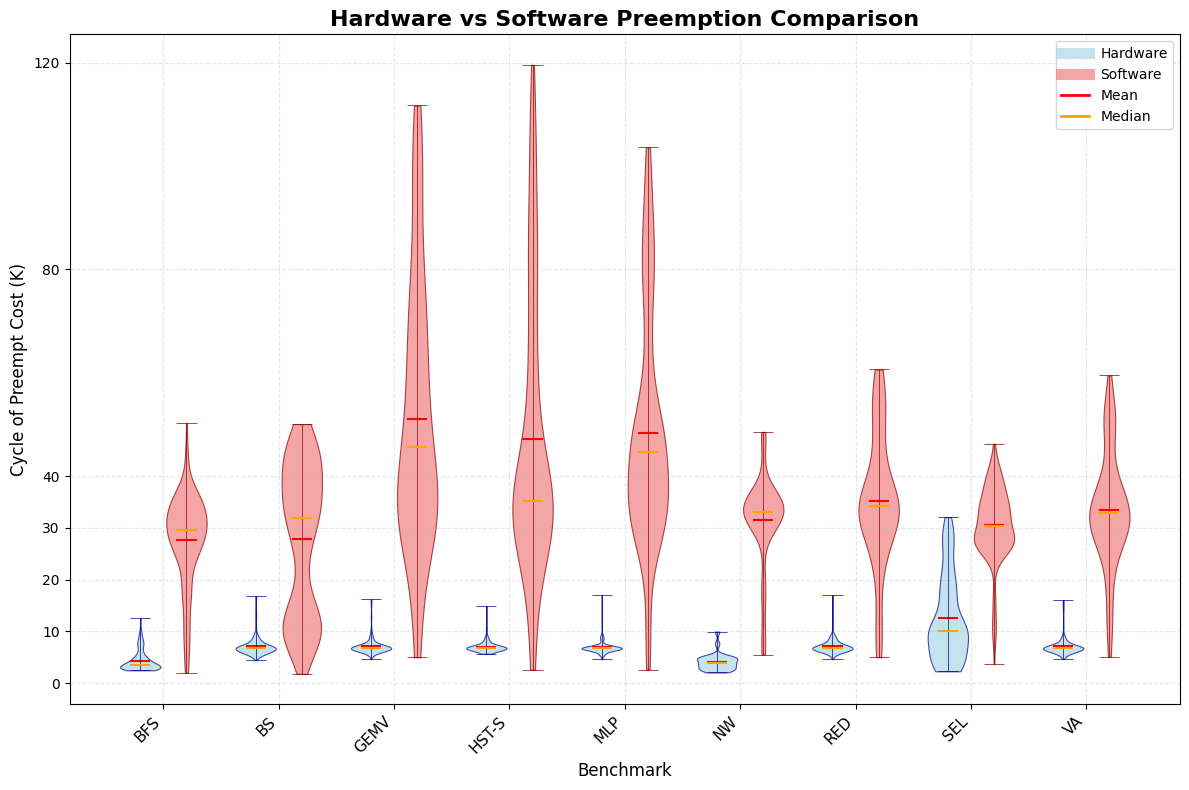


Chart saved as: preempt_comparison.png
Analysis completed!


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from io import StringIO
from matplotlib.lines import Line2D
import os

def stratified_sampling(values, target_size, seed=42):
    """
    Perform stratified sampling based on distribution
    
    Parameters:
    values: Original data
    target_size: Target sample size
    seed: Random seed
    
    Returns:
    Sampled data
    """
    np.random.seed(seed)
    
    if len(values) <= target_size:
        return values
    
    # Calculate quantiles as stratification basis
    n_strata = min(10, len(values) // 20)  # Maximum 10 strata, at least 20 samples per stratum
    if n_strata < 2:
        # If too few strata, perform direct random sampling
        indices = np.random.choice(len(values), target_size, replace=False)
        return [values[i] for i in sorted(indices)]
    
    # Sort by value and stratify
    sorted_values = sorted(values)
    strata_size = len(sorted_values) // n_strata
    
    sampled_values = []
    samples_per_stratum = target_size // n_strata
    remaining_samples = target_size % n_strata
    
    for i in range(n_strata):
        start_idx = i * strata_size
        if i == n_strata - 1:
            # Last stratum contains all remaining elements
            end_idx = len(sorted_values)
        else:
            end_idx = (i + 1) * strata_size
        
        stratum = sorted_values[start_idx:end_idx]
        
        # Calculate number of samples to draw from this stratum
        n_samples = samples_per_stratum
        if i < remaining_samples:
            n_samples += 1
        
        if len(stratum) <= n_samples:
            sampled_values.extend(stratum)
        else:
            indices = np.random.choice(len(stratum), n_samples, replace=False)
            sampled_values.extend([stratum[idx] for idx in indices])
    
    return sampled_values

def balance_preempt_data_dual(df_hw, df_sw):
    """
    Balance preempt data volume from two data sources, ignoring zero values
    For quantities less than 250, sample by distribution; for quantities greater than 250, subsample by distribution
    
    Parameters:
    df_hw: Hardware data
    df_sw: Software data
    
    Returns:
    balanced_hw, balanced_sw, final_count
    """
    
    # Get preempt columns
    preempt_columns_hw = [col for col in df_hw.columns if col.startswith('preempt_')]
    preempt_columns_sw = [col for col in df_sw.columns if col.startswith('preempt_')]
    
   
    
    hw_data = {}
    sw_data = {}
    hw_counts = {}
    sw_counts = {}
    
    # Process hardware data
    for idx, row in df_hw.iterrows():
        code = row['code']
        preempt_values = row[preempt_columns_hw].values
        
        # Debug: Display raw data
        print(f"\n{code} - Hardware raw data sample: {preempt_values[:10]}")
        print(f"{code} - Hardware data type: {type(preempt_values[0]) if len(preempt_values) > 0 else 'empty'}")
        print(f"{code} - Hardware unique values: {np.unique(preempt_values[~pd.isna(preempt_values)])[:10]}")
        
        # Remove NaN values, but don't filter zero values yet to see if there's data
        non_nan_values = preempt_values[~pd.isna(preempt_values)]
        print(f"{code} - Hardware count after removing NaN: {len(non_nan_values)}")
        
        # Check zero value situation
        zero_count = np.sum(non_nan_values == 0)
        non_zero_count = np.sum(non_nan_values != 0)
        print(f"{code} - Hardware zero count: {zero_count}, non-zero count: {non_zero_count}")
        
        # Temporarily don't filter zero values, first see how much non-zero data there is
        if non_zero_count > 0:
            valid_values = non_nan_values[non_nan_values != 0]
        else:
            # If no non-zero values, keep all non-NaN values (including zeros)
            valid_values = non_nan_values
            print(f"Warning: {code} - Hardware has no non-zero data, keeping all data")
        
        hw_counts[code] = len(valid_values)
        hw_data[code] = valid_values.tolist()
    
    # Process software data
    for idx, row in df_sw.iterrows():
        code = row['code']
        preempt_values = row[preempt_columns_sw].values
        
        # Debug: Display raw data
        print(f"\n{code} - Software raw data sample: {preempt_values[:10]}")
        print(f"{code} - Software data type: {type(preempt_values[0]) if len(preempt_values) > 0 else 'empty'}")
        print(f"{code} - Software unique values: {np.unique(preempt_values[~pd.isna(preempt_values)])[:10]}")
        
        # Remove NaN values
        non_nan_values = preempt_values[~pd.isna(preempt_values)]
        print(f"{code} - Software count after removing NaN: {len(non_nan_values)}")
        
        # Check zero value situation
        zero_count = np.sum(non_nan_values == 0)
        non_zero_count = np.sum(non_nan_values != 0)
        print(f"{code} - Software zero count: {zero_count}, non-zero count: {non_zero_count}")
        
        # Temporarily don't filter zero values, first see how much non-zero data there is
        if non_zero_count > 0:
            valid_values = non_nan_values[non_nan_values != 0]
        else:
            # If no non-zero values, keep all non-NaN values (including zeros)
            valid_values = non_nan_values
            print(f"Warning: {code} - Software has no non-zero data, keeping all data")
        
        sw_counts[code] = len(valid_values)
        sw_data[code] = valid_values.tolist()
    
    # Find common codes with valid data on both sides
    common_codes = set(hw_data.keys()) & set(sw_data.keys())
    valid_codes = []
    
    for code in common_codes:
        if len(hw_data[code]) > 0 and len(sw_data[code]) > 0:
            valid_codes.append(code)
        else:
            print(f"Skipping {code}: HW data count={len(hw_data[code])}, SW data count={len(sw_data[code])}")
    
    if not valid_codes:
        raise ValueError("No valid data found for comparison! All data may be zeros or NaN")
    
    balanced_hw = {}
    balanced_sw = {}
    
    print("\nData balancing process:")
    print("Code     HW_orig  HW_proc   SW_orig  SW_proc   Strategy")
    print("-" * 60)
    
    for code in valid_codes:
        hw_values = hw_data[code]
        sw_values = sw_data[code]
        hw_count = len(hw_values)
        sw_count = len(sw_values)
        
        # Decide processing strategy based on data volume
        min_count = min(hw_count, sw_count)
        
        if min_count < 250:
            # Less than 250, sample by distribution to 250 (if possible)
            target_size = min(250, min_count)
            strategy = "Sample to 250" if min_count >= 50 else "Keep original"
        else:
            # 250 or more, subsample by distribution to 250
            target_size = 250
            strategy = "Subsample to 250"
        
        # Process hardware data
        if hw_count <= target_size:
            balanced_hw[code] = hw_values
            hw_final_count = hw_count
        else:
            balanced_hw[code] = stratified_sampling(hw_values, target_size)
            hw_final_count = target_size
        
        # Process software data
        if sw_count <= target_size:
            balanced_sw[code] = sw_values
            sw_final_count = sw_count
        else:
            balanced_sw[code] = stratified_sampling(sw_values, target_size)
            sw_final_count = target_size
        
        print(f"{code:<8} {hw_count:<7} {hw_final_count:<9} {sw_count:<7} {sw_final_count:<9} {strategy}")
    
    return balanced_hw, balanced_sw, valid_codes

def create_dual_violin_plot(hw_folder='hardware', sw_folder='software'):
    """
    Create dual folder preempt data comparison violin plot with custom y-axis ticks
    
    Parameters:
    hw_folder: Hardware folder path
    sw_folder: Software folder path
    """
    
    # Read data
    hw_csv_path = os.path.join(hw_folder, 'preempt.csv')
    sw_csv_path = os.path.join(sw_folder, 'preempt.csv')
    
    if not os.path.exists(hw_csv_path):
        raise FileNotFoundError(f"File not found: {hw_csv_path}")
    if not os.path.exists(sw_csv_path):
        raise FileNotFoundError(f"File not found: {sw_csv_path}")
    
    df_hw = pd.read_csv(hw_csv_path)
    df_sw = pd.read_csv(sw_csv_path)
    # Remove rows where code is 'TS'
    df_hw = df_hw[df_hw['code'] != 'TS']
    df_sw = df_sw[df_sw['code'] != 'TS']
    
    # Divide all preempt data by 1000
    preempt_columns_hw = [col for col in df_hw.columns if col.startswith('preempt_')]
    preempt_columns_sw = [col for col in df_sw.columns if col.startswith('preempt_')]
    
    df_hw[preempt_columns_hw] = df_hw[preempt_columns_hw] / 1000
    df_sw[preempt_columns_sw] = df_sw[preempt_columns_sw] / 1000
    
    # Balance data
    balanced_hw, balanced_sw, valid_codes = balance_preempt_data_dual(df_hw, df_sw)
    
    # Set Chinese font
    plt.rcParams['font.sans-serif'] = ['SimHei', 'DejaVu Sans', 'Arial Unicode MS']
    plt.rcParams['axes.unicode_minus'] = False
    
    # Create figure
    fig, ax = plt.subplots(1, 1, figsize=(12, 8))
    
    # Prepare data
    codes = sorted(list(valid_codes))
    hw_data_list = [balanced_hw[code] for code in codes]
    sw_data_list = [balanced_sw[code] for code in codes]
    
    # Set positions - hardware on left (-.2), software on right (+.2)
    positions_hw = [i + 1 - 0.2 for i in range(len(codes))]
    positions_sw = [i + 1 + 0.2 for i in range(len(codes))]
    
    # Color settings
    color_hw = 'lightblue'
    color_sw = 'lightcoral'
    
    # Draw hardware violin plot (left side)
    violin_parts_hw = ax.violinplot(hw_data_list, 
                                   positions=positions_hw,
                                   showmeans=True,
                                   showmedians=True,
                                   showextrema=True,
                                   widths=0.35)
    
    for pc in violin_parts_hw['bodies']:
        pc.set_facecolor(color_hw)
        pc.set_alpha(0.7)
        pc.set_edgecolor('darkblue')
        pc.set_linewidth(0.8)
    
    violin_parts_hw['cmeans'].set_color('red')
    violin_parts_hw['cmedians'].set_color('orange')
    violin_parts_hw['cbars'].set_color('darkblue')
    violin_parts_hw['cmins'].set_color('darkblue')
    violin_parts_hw['cmaxes'].set_color('darkblue')
    violin_parts_hw['cbars'].set_linewidth(0.5)
    violin_parts_hw['cmins'].set_linewidth(0.5)
    violin_parts_hw['cmaxes'].set_linewidth(0.5)
    
    # Draw software violin plot (right side)
    violin_parts_sw = ax.violinplot(sw_data_list, 
                                   positions=positions_sw,
                                   showmeans=True,
                                   showmedians=True,
                                   showextrema=True,
                                   widths=0.35)
    
    for pc in violin_parts_sw['bodies']:
        pc.set_facecolor(color_sw)
        pc.set_alpha(0.7)
        pc.set_edgecolor('darkred')
        pc.set_linewidth(0.8)
    
    violin_parts_sw['cmeans'].set_color('red')
    violin_parts_sw['cmedians'].set_color('orange')
    violin_parts_sw['cbars'].set_color('darkred')
    violin_parts_sw['cmins'].set_color('darkred')
    violin_parts_sw['cmaxes'].set_color('darkred')
    violin_parts_sw['cbars'].set_linewidth(0.5)
    violin_parts_sw['cmins'].set_linewidth(0.5)
    violin_parts_sw['cmaxes'].set_linewidth(0.5)
    
    # Get current y-axis maximum to determine tick range
    y_max = ax.get_ylim()[1]
    
    # Set custom y-axis ticks: normal intervals below 40, every 40 above 40
    yticks = []
    
    # Ticks below 40 (approximately every 10 based on original plot)
    yticks.extend([0, 10, 20, 30, 40])
    
    # Ticks above 40, every 40
    current_tick = 80  # Start from 80 (40+40)
    while current_tick <= y_max:  # Ensure coverage of all data
        yticks.append(current_tick)
        current_tick += 40
    
    # Apply custom ticks
    ax.set_yticks(yticks)
    ax.set_yticklabels([str(int(tick)) for tick in yticks])
    
    # Set chart properties
    ax.set_title('Hardware vs Software Preemption Comparison', fontsize=16, fontweight='bold')
    ax.set_xticks(range(1, len(codes) + 1))
    ax.set_xticklabels(codes, rotation=45, ha='right', fontsize=11)
    ax.set_xlabel('Benchmark', fontsize=12)
    ax.set_ylabel('Cycle of Preempt Cost (K)', fontsize=12)
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Add legend
    legend_elements = [
        Line2D([0], [0], color=color_hw, lw=8, alpha=0.7, label='Hardware'),
        Line2D([0], [0], color=color_sw, lw=8, alpha=0.7, label='Software'),
        Line2D([0], [0], color='red', lw=2, label='Mean'),
        Line2D([0], [0], color='orange', lw=2, label='Median')
    ]
    ax.legend(handles=legend_elements, loc='upper right', fontsize=10)
    
    plt.tight_layout()
    
    # Statistical analysis comparison
    print("\nStatistical analysis comparison:")
    print("Code     HW_mean  SW_mean  Diff     HW_median SW_median")
    print("-" * 55)
    
    for i, code in enumerate(codes):
        hw_values = np.array(hw_data_list[i])
        sw_values = np.array(sw_data_list[i])
        
        hw_mean = hw_values.mean()
        sw_mean = sw_values.mean()
        diff = abs(hw_mean - sw_mean)
        
        hw_median = np.median(hw_values)
        sw_median = np.median(sw_values)
        
        print(f"{code:<8} {hw_mean:<8.2f} {sw_mean:<8.2f} {diff:<8.3f} {hw_median:<8.2f} {sw_median:<8.2f}")
    
    plt.show()
    
    # Save figure
    fig.savefig('preempt_comparison.png', dpi=300, bbox_inches='tight')
    print(f"\nChart saved as: preempt_comparison.png")
    
    return df_hw, df_sw, balanced_hw, balanced_sw

# Run analysis
if __name__ == "__main__":
    # Use CSV files from two folders
    try:
        df_hw, df_sw, balanced_hw, balanced_sw = create_dual_violin_plot('hardware', 'software')
        print("Analysis completed!")
    except FileNotFoundError as e:
        print(f"Error: {e}")
        print("Please ensure hardware/preempt.csv and software/preempt.csv files exist")
    except Exception as e:
        print(f"Runtime error: {e}")